# Homework 4 — Evaluation Metrics for Classification

**Dataset:** course lead scoring. **Target:** `converted` (1 = the lead bought the course, 0 = didn't).

**Mental picture used throughout:** a sales team has a list of leads. The model gives every lead a score from 0 to 1, and the team calls everyone above a **cutoff (threshold)**.

| Section | Question it answers |
|---|---|
| Data prep | Is the data clean and split fairly? |
| Q1 Feature AUC | Which single feature is most useful? |
| Q2 Model AUC | Is the trained model good? |
| Random / ideal model | What do "no skill" and "perfect" look like? |
| Q3 Precision & recall | Where do they cross? |
| Q4 F1 | Which cutoff balances both best? |
| Q5 K-fold | How stable is the score? |
| Q6 Tune C | Which regularization works best? |

In [1]:
# !wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

## 1. Load the data

Read the CSV into a DataFrame `df`. Useful checks: `df.isnull().sum()` (missing values per column) and `df.dtypes` (text vs number columns).

In [2]:
import pandas as pd
df = pd.read_csv('course_lead_scoring_2026.csv')

## 2. Separate categorical and numerical columns

Text columns and number columns need different handling (different fill values, different encoding).

⚠️ `numerical_columns` here also contains the target `converted` — fine for filling NaNs, but it must never be used as a feature.

In [3]:
categorical_columns = df.select_dtypes(include=['object']).columns
numerical_columns = df.columns.difference(categorical_columns).tolist()

/var/folders/3n/ltmv65_n0lq0g_dyltmjkpbw0000gn/T/ipykernel_90308/618124649.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object']).columns


## 3. Fill missing values

- Categorical → `'NA'`: "missing" becomes its own category (it may carry signal).
- Numerical → `0`.

**Why:** the model can't do math on NaN — one missing value breaks training (`ValueError: Input contains NaN`).

⚠️ Always assign back into `df` (`df[cols] = ...`). Filling a *copy* leaves NaNs in the data you split later.

In [4]:
df[categorical_columns] = df[categorical_columns].fillna('NA')
df[numerical_columns] = df[numerical_columns].fillna(0)

## 4. Split the dataset

**What:** split into train 60% / validation 20% / test 20% using `split_dataset` from `utils.py`.

**Why:**
- **Train** → the model learns from it.
- **Validation** → we compare settings on it.
- **Test** → touched once, at the very end, for an honest final score.

`random_state=1` makes the split the same every run. `X_*` = features, `y_*` = the target (0/1).

In [5]:
from utils import split_dataset

# train / val / test (60/20/20)
X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(
    df, target='converted', test_size=0.2, val_size=0.2, random_state=1
)

## Q1. ROC AUC of each numerical feature

**Idea:** use a raw feature *as if it were the prediction score* and ask: do buyers tend to have higher values than non-buyers?

| AUC | Meaning |
|---|---|
| 1.0 | perfect separator |
| 0.5 | useless (coin flip) |
| < 0.5 | works backwards → flip the sign (`-X[col]`) and the AUC becomes `1 - AUC` |

Computed on **train only**, so nothing leaks from validation/test.

**Result:** `lead_score` is the best single feature (**0.788**), then `interaction_count` (0.765), `number_of_courses_viewed` (0.723), `annual_income` (0.608).

In [6]:
from sklearn.metrics import roc_auc_score
numerical = X_train.select_dtypes("number").columns   # or list them explicitly
numerical  # or list them explicitly

Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'],
      dtype='str')

In [7]:
for col in numerical:
    auc = roc_auc_score(y_train, X_train[col])
    if auc < 0.5:                                        # reverse relationship → invert
        auc = roc_auc_score(y_train, -X_train[col])
        print(f"{col:>10}: {auc:.3f} (inverted)")
    else:
        print(f"{col:>10}: {auc:.3f} (Regular)")

annual_income: 0.608 (Regular)
number_of_courses_viewed: 0.723 (Regular)
interaction_count: 0.765 (Regular)
lead_score: 0.788 (Regular)


## Q2. Train logistic regression and measure AUC

**Steps:**
1. `DictVectorizer` turns each row into numbers (one-hot for text columns). `fit_transform` on **train**, only `transform` on validation — so both have the same columns.
2. Train `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`.
3. `predict_proba(...)[:, 1]` → probability that each lead converts. AUC needs probabilities, not 0/1 labels.

**Result:** validation AUC = **0.732**.

💡 Interesting: this is *lower* than `lead_score` alone (0.788). Reason: `annual_income` is in the tens of thousands and not scaled, so it dominates the model. Scaling the numbers (`StandardScaler`) would push AUC to ~0.79.

In [8]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

dv = DictVectorizer(sparse=False)

train_dicts = X_train.to_dict(orient='records')
X_train_enc = dv.fit_transform(train_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train_enc, y_train)

# validation: transform only, never fit again
val_dicts = X_val.to_dict(orient='records')
X_val_enc = dv.transform(val_dicts)

y_pred = model.predict_proba(X_val_enc)[:, 1]
print(round(roc_auc_score(y_val, y_pred), 3))


0.732


## Random model (baseline)

**What:** a fake model that gives every lead a random score between 0 and 1.

**Why:** it's the "no skill" baseline. Our real model must clearly beat it.

**Result:** random accuracy at 0.5 ≈ **0.506** — basically a coin flip.

In [9]:
import numpy as np
np.random.seed(1)

In [10]:
y_random = np.random.uniform(0, 1, size=len(y_val))
y_random.round(3)

array([0.417, 0.72 , 0.   , 0.302, 0.147, 0.092, 0.186, 0.346, 0.397,
       0.539, 0.419, 0.685, 0.204, 0.878, 0.027, 0.67 , 0.417, 0.559,
       0.14 , 0.198, 0.801, 0.968, 0.313, 0.692, 0.876, 0.895, 0.085,
       0.039, 0.17 , 0.878, 0.098, 0.421, 0.958, 0.533, 0.692, 0.316,
       0.687, 0.835, 0.018, 0.75 , 0.989, 0.748, 0.28 , 0.789, 0.103,
       0.448, 0.909, 0.294, 0.288, 0.13 , 0.019, 0.679, 0.212, 0.266,
       0.492, 0.053, 0.574, 0.147, 0.589, 0.7  , 0.102, 0.414, 0.694,
       0.414, 0.05 , 0.536, 0.664, 0.515, 0.945, 0.587, 0.903, 0.137,
       0.139, 0.807, 0.398, 0.165, 0.928, 0.348, 0.751, 0.726, 0.883,
       0.624, 0.751, 0.349, 0.27 , 0.896, 0.428, 0.965, 0.663, 0.622,
       0.115, 0.949, 0.45 , 0.578, 0.408, 0.237, 0.903, 0.574, 0.003,
       0.617, 0.327, 0.527, 0.886, 0.357, 0.909, 0.623, 0.016, 0.929,
       0.691, 0.997, 0.172, 0.137, 0.933, 0.697, 0.066, 0.755, 0.754,
       0.923, 0.712, 0.124, 0.02 , 0.026, 0.028, 0.246, 0.86 , 0.539,
       0.553, 0.842,

In [11]:
((y_random >= 0.5) == y_val).mean().item()  # accuracy

0.506

### `tpr_fpr()` — evaluate at every threshold 0.00, 0.01, … 1.00

For each cutoff it sorts every lead into one of 4 boxes:

| | Model says "buy" (called) | Model says "no" (skipped) |
|---|---|---|
| **Actually bought** | **TP** – good call ✅ | **FN** – missed sale ❌ |
| **Didn't buy** | **FP** – wasted call ❌ | **TN** – correctly skipped ✅ |

Then it computes:

- **TPR** (true positive rate, = recall) = TP / (TP + FN) → *share of buyers we caught*
- **FPR** (false positive rate) = FP / (FP + TN) → *share of non-buyers we wrongly called*

Raising the cutoff lowers both. A good model lowers FPR **faster** than TPR.

In [12]:
def tpr_fpr(y_val, y_pred, threshold=0.5):

    scores = []
    thresholds = np.linspace(0, 1, 101)
    for threshold in thresholds:
        pred_pos = (y_pred >= threshold)
        pred_neg = (y_pred < threshold)

        actual_pos = (y_val == 1)
        actual_neg = (y_val == 0)
        
        tn = (pred_neg & actual_neg).sum()
        fp = (pred_pos & actual_neg).sum()
        fn = (pred_neg & actual_pos).sum()
        tp = (pred_pos & actual_pos).sum()

        scores.append((threshold, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)
    scores = np.array(scores)

    df_scores['tpr'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fn'])
    df_scores['fpr'] = df_scores['fp'] / (df_scores['fp'] + df_scores['tn'])

    return df_scores

**Reading the random model's table:** TPR ≈ FPR at every threshold.

Random scores lose buyers and non-buyers at the *same rate*, so filtering gives no benefit — skipping 10% of wasted calls also loses 10% of sales.

In [13]:
tpr_fpr_rand = tpr_fpr(y_val, y_random).round(3)
tpr_fpr_rand[:10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.00,586,414,0,0,1.000,1.000
1,0.01,578,412,8,2,0.986,0.995
2,0.02,568,402,18,12,0.969,0.971
3,0.03,562,395,24,19,0.959,0.954
4,0.04,554,394,32,20,0.945,0.952
5,0.05,552,391,34,23,0.942,0.944
6,0.06,545,389,41,25,0.930,0.940
7,0.07,538,386,48,28,0.918,0.932
8,0.08,534,380,52,34,0.911,0.918
9,0.09,530,378,56,36,0.904,0.913


## ROC curve — model vs random

Plot TPR (y) against FPR (x) for every threshold.

- **Random** → follows the diagonal.
- **Our model** → bows toward the top-left corner (catches more buyers for the same number of wasted calls).
- The **space between the curves** is what the model learned.

In [14]:
from matplotlib import pyplot as plt

df_model = tpr_fpr(y_val, y_pred)
df_rand  = tpr_fpr(y_val, y_random)

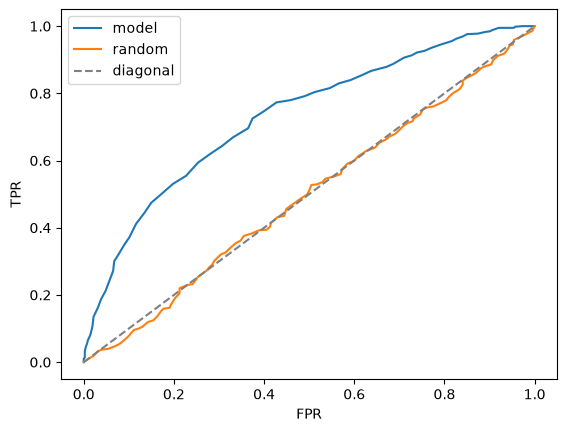

In [15]:

for d in (df_model, df_rand):
    d['accuracy'] = (d.tp + d.tn) / (d.tp + d.fp + d.fn + d.tn)

plt.plot(df_model.fpr, df_model.tpr, label='model')
plt.plot(df_rand.fpr, df_rand.tpr, label='random')
plt.plot([0, 1], [0, 1], '--', color='grey', label='diagonal')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend()


## Compare model vs random with AUC

**AUC = area under the ROC curve.**

**Results:** model **0.732** vs random **≈ 0.5** → the model is clearly better than chance.

(The random AUC changes slightly each run, since it depends on the random numbers drawn.)

Plain-English meaning: *pick one random buyer and one random non-buyer — AUC is the chance the model gives the buyer the higher score.*

In [16]:
from sklearn.metrics import auc

df_model = tpr_fpr(y_val, y_pred)
df_rand  = tpr_fpr(y_val, y_random)

# AUC measures the area under the ROC curve. 
# The higher the AUC, the better the model is 
# at distinguishing between positive and negative classes.
true_model_auc = auc(df_model.fpr, df_model.tpr)
random_model_auc = auc(df_rand.fpr, df_rand.tpr)

print(f"Model AUC (from table) : {auc(df_model.fpr, df_model.tpr):.3f}")
print(f"Random AUC (from table): {auc(df_rand.fpr, df_rand.tpr):.3f}")

if true_model_auc > random_model_auc:
    print("The model already performs better than random.")
else:
    print("The model does not perform better than random.")

Model AUC (from table) : 0.732
Random AUC (from table): 0.495
The model already performs better than random.


## Ideal (perfect) model

**What:** sort all leads so every non-buyer comes first, then give evenly spaced scores — every buyer scores above every non-buyer.

**Why:** shows the best possible behaviour (AUC = 1.0): there is one cutoff where TPR = 1 and FPR = 0.

`np.repeat([0, 1], [actual_neg, actual_pos])` → 414 zeros (non-buyers) followed by 586 ones (buyers).

The perfect cutoff = share of non-buyers = `1 - y_val.mean()` = **0.414**. At that cutoff the ideal model's accuracy is **1.0**.

In [17]:
actual_pos = (y_val == 1).sum()
actual_neg = (y_val == 0).sum()

y_ideal = np.repeat([0, 1], [actual_neg, actual_pos])  # non-buyers first, then buyers

y_ideal_predict = np.linspace(0, 1, len(y_val))

ideal_threshold = 1 - y_val.mean()  # share of non-buyers = the perfect cutoff
accuracy_ideal = ((y_ideal_predict >= ideal_threshold) == y_ideal).mean()
accuracy_ideal.item()  # ideal predictions

1.0

In [18]:
1 - y_val.mean()

np.float64(0.41400000000000003)

### Ideal model plot

**Reading the ideal plot:** FPR drops to 0 at ≈ 0.41 while TPR is still 1 — then, past that boundary, TPR falls. Real models can't do this; their curves overlap and the cutoff becomes a trade-off.

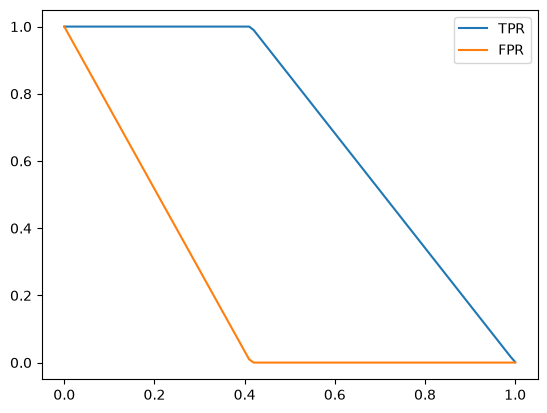

In [19]:
df_ideal = tpr_fpr(y_ideal, y_ideal_predict)
plt.plot(df_ideal.threshold, df_ideal['tpr'], label = 'TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label = 'FPR')
plt.legend()

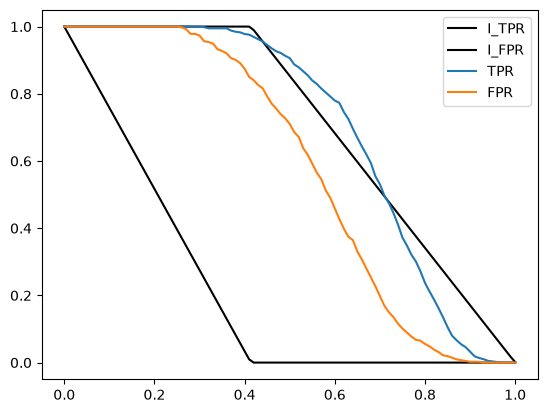

In [20]:
df_ideal = tpr_fpr(y_ideal, y_ideal_predict)
plt.plot(df_ideal.threshold, df_ideal['tpr'], label = 'I_TPR', color = 'black')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label = 'I_FPR', color = 'black')

# plt.plot(df_rand.threshold, df_rand['tpr'], label = 'R_TPR')
# plt.plot(df_rand.threshold, df_rand['fpr'], label = 'R_FPR')

plt.plot(df_model.threshold, df_model['tpr'], label = 'TPR')
plt.plot(df_model.threshold, df_model['fpr'], label = 'FPR')

plt.legend()

## ROC curve (model vs diagonal)

ROC curve of the model: **FPR on the x-axis, TPR on the y-axis**. The dashed diagonal is what a random model would give.

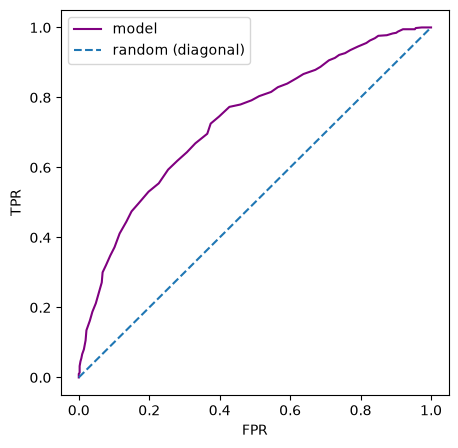

In [21]:
plt.figure(figsize=(5,5))
# plt.plot(df_ideal.fpr, df_ideal.tpr, label = 'ideal', color = 'Orange')
plt.plot(df_model.fpr, df_model.tpr, label = 'model', color = 'Purple')
# plt.plot(df_rand.fpr, df_rand.tpr, label = 'random', color = 'Green')
plt.plot([0,1], [0,1], label = 'random (diagonal)', linestyle = '--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

## Precision and recall

- **Precision** = TP / (TP + FP) → *of the leads I called, how many bought?* (how clean is my call list)
- **Recall** = TP / (TP + FN) → *of all buyers, how many did I call?* (how complete is my call list) — same as TPR

**Tug-of-war:** raise the threshold → precision ⬆, recall ⬇. Lower it → the opposite.

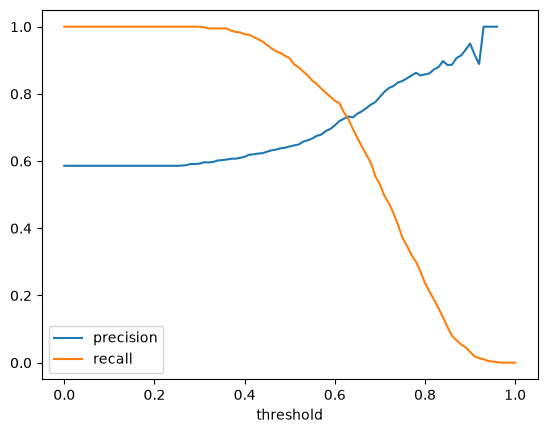

In [22]:
df_scores = tpr_fpr(y_val, y_pred)

df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold'); plt.legend()


ℹ️ `NaN` at the highest thresholds is expected: the model predicts nobody as a buyer, so precision = 0 / 0. The next section handles this by setting it to 0.

In [23]:
df_scores['precision']

0      0.586
1      0.586
2      0.586
3      0.586
4      0.586
       ...  
96     1.000
97       NaN
98       NaN
99       NaN
100      NaN
Name: precision, Length: 101, dtype: float64

**Reading the plot:** recall starts at 1.0 and falls as the threshold rises; precision generally rises, because the leads we still call are the ones the model is most confident about.

## Q3. Where do precision and recall cross?

Compute both for thresholds 0.00 → 1.00 (step 0.01 = 101 thresholds).

`if (tp + fp) > 0 else 0` avoids dividing by zero when the model predicts nobody as a buyer (high thresholds).

In [24]:
thresholds = np.arange(0.0, 1.01, 0.01)
scores = []

for t in thresholds:
    pred_pos = (y_pred >= t)

    tp = (pred_pos & (y_val == 1)).sum()
    fp = (pred_pos & (y_val == 0)).sum()
    fn = (~pred_pos & (y_val == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn)

    scores.append((t, precision, recall))

df_pr = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])
df_pr.round(3)



,threshold,precision,recall
0,0.00,0.586,1.000
1,0.01,0.586,1.000
2,0.02,0.586,1.000
3,0.03,0.586,1.000
4,0.04,0.586,1.000
...,...,...,...
96,0.96,1.000,0.002
97,0.97,0.000,0.000
98,0.98,0.000,0.000
99,0.99,0.000,0.000


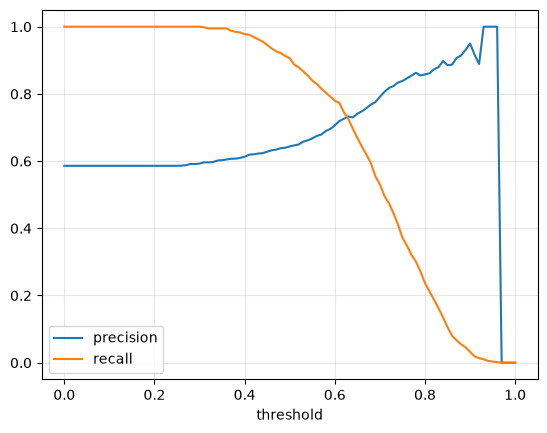

In [25]:
plt.plot(df_pr.threshold, df_pr.precision, label='precision')
plt.plot(df_pr.threshold, df_pr.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.grid(alpha=0.3)


**How:** take the first threshold where precision ≥ recall.

⚠️ Don't use "smallest |precision − recall|": at high thresholds both are 0, which fakes a perfect match.

**Result:** they cross at **≈ 0.63** (0.62: P 0.726 / R 0.746 → 0.63: P 0.733 / R 0.725). At this cutoff ~3 in 4 calls are sales and we reach ~3 in 4 buyers.

In [26]:
cross = df_pr[df_pr.precision >= df_pr.recall].iloc[0]   # first threshold where precision catches up
cross


threshold    0.630000
precision    0.732759
recall       0.725256
Name: 63, dtype: float64

## Q4. Best F1 threshold

**F1 = 2·P·R / (P + R)** — the *harmonic* mean. It's high only when **both** precision and recall are high (P = 1.0, R = 0.02 → F1 = 0.04, not 0.51).

**Result:** best F1 = **0.758** at threshold **0.41** (precision 0.62, recall 0.98).

Why lower than the 0.63 crossing? ~59% of leads convert, so calling more people costs little precision but gains a lot of recall. The F1 curve is quite flat, so nearby thresholds work almost as well.

In [27]:
df_pr['f1'] = 2 * df_pr.precision * df_pr.recall / (df_pr.precision + df_pr.recall)
df_pr['f1'] = df_pr['f1'].fillna(0)   # where P = R = 0, 0/0 gives NaN

best = df_pr.loc[df_pr.f1.idxmax()]
round(best.threshold.item(), 3)


0.41

**Sanity check:** AUC from our own 101-threshold table vs scikit-learn's exact `roc_auc_score` — they should be nearly identical (small difference = only 101 thresholds).

In [28]:
from sklearn.metrics import auc
round(auc(df_model['fpr'], df_model['tpr']), 9)

0.731560485

In [29]:
round(roc_auc_score(y_val, y_pred),9)

0.731822229

## What AUC really means — simulation

**What:** estimate AUC by simulation — repeatedly pick a random buyer and a random non-buyer, and count how often the buyer has the higher score.

**Result:** ≈ **0.73**, matching the real AUC (0.732). The value changes a little each run (random sampling) — more iterations → closer.

This proves what AUC *means*: the probability of ranking a buyer above a non-buyer.

In [30]:
import random

pos = y_pred[y_val == 1]   # scores of buyers
neg = y_pred[y_val == 0]   # scores of non-buyers

success = 0
iterations = 1000

for i in range(iterations):
    rand_pos = random.randint(0, len(pos) - 1)
    rand_neg = random.randint(0, len(neg) - 1)
    if pos[rand_pos] > neg[rand_neg]:
        success += 1

success / iterations


0.752

### Helper functions

## Q5. K-fold cross-validation

**Problem:** one validation split = one score. It might be a lucky (or unlucky) slice.

**Solution:** split the data into 5 parts. Train 5 times; each time a different part is the test fold:

```
Round 1: [TEST][train][train][train][train]
Round 2: [train][TEST][train][train][train]
...
```

- **Mean** of the 5 AUCs → typical performance.
- **Std** → how much it varies. Small = stable, trustworthy.

These helper functions just create the KFold / vectorizer / model with fixed settings.

In [31]:
def get_kfold():
    return KFold(n_splits=5, shuffle=True, random_state=1)

def get_dict_vectorizer():
    return DictVectorizer(sparse=False)

def get_regression_model(c=1.0, iteration=1):
    return LogisticRegression(solver='liblinear', C=c, max_iter=iteration)

**Result:** **0.732 ± 0.007** → the std is small, so the model is stable from fold to fold.

`df_full_train` = train + validation (4,000 rows); the test set stays untouched. The folds are made from the same `df_full_train` we slice.

In [32]:
# One validation split gives you one score. 
# K-fold gives you K scores: their average 
# tells you how good the model is, and their 
# spread tells you how much to trust that number.
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split

kfold = get_kfold()
scores = []

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    y_tr = df_tr.converted.values
    y_va = df_va.converted.values

    dv = get_dict_vectorizer()
    X_tr = dv.fit_transform(df_tr.drop(columns='converted').to_dict(orient='records'))
    X_va = dv.transform(df_va.drop(columns='converted').to_dict(orient='records'))

    model = get_regression_model(c=1.0, iteration=1000)
    model.fit(X_tr, y_tr)

    y_pred_va = model.predict_proba(X_va)[:, 1]
    scores.append(roc_auc_score(y_va, y_pred_va))

print(f"Avg AUC : {np.mean(scores):.3f} ± SD : {np.std(scores):.3f}")
scores


Avg AUC : 0.732 ± SD : 0.007


[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

### Cross-validation run (C = 1.0)

## Q6. Tune the regularization parameter C

**C** controls how strongly weights are pushed toward 0:
- **Small C** → strong penalty → simpler model (can underfit).
- **Large C** → weak penalty → fits training data more closely (can overfit).

**Pick:** highest mean AUC → if tied, lowest std → if still tied, smallest C.

**Results:**

| C | mean AUC | std |
|---|---|---|
| 0.000001 | 0.617 | 0.019 — too strong, model barely learns |
| **0.001** | **0.749** | 0.010 — **best** |
| 1 | 0.732 | 0.007 |

C = 0.001 wins partly because it tames the unscaled `annual_income`. With scaled features every C gives ≈ 0.79.

In [33]:
from sklearn.model_selection import KFold

def train(df_train, C):
    dicts = df_train.drop(columns='converted').to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, df_train.converted.values)
    return dv, model

def predict(df, dv, model):
    assert 'converted' in df.columns, "target column 'converted' is missing"

    dicts = df.drop(columns='converted').to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

kfold = KFold(n_splits=5, shuffle=True, random_state=1)   # same as previous question

for C in [0.000001, 0.001, 1]:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        dv, model = train(df_tr, C)
        y_pred_va = predict(df_va, dv, model)
        scores.append(roc_auc_score(df_va.converted.values, y_pred_va))

    print(f"C={C} mean={np.mean(scores):.3f}  std={np.std(scores):.3f}")


C=1e-06 mean=0.617  std=0.019


C=0.001 mean=0.749  std=0.010


C=1 mean=0.732  std=0.007


### Try each C with 5-fold CV

## Final check on the test set

Retrain on **train + validation** (`df_full_train`) with the best C = 0.001, then score the **test set once**.

**Result:** test AUC = **0.738** — close to the cross-validation mean, so the model generalizes as expected.

⚠️ Use `df_test` *and* `df_test.converted` from the same split — `y_test` from `split_dataset` comes from a different split.

In [34]:
dv_full, model_full = train(df_full_train, C=0.001)
y_pred_test = predict(df_test, dv_full, model_full)        # pass the DataFrame

auc = roc_auc_score(df_test.converted.values, y_pred_test)  # labels from the same df_test
round(auc, 3)


0.738